<a href="https://colab.research.google.com/github/Nafila1234/smart-waste-multi-agent/blob/main/preprocessing_data%2Bdecision_tree_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import pandas as pd


In [8]:
base = "/content/drive/MyDrive/Dataset/"

twin_raw = pd.read_csv(base + "digital_twin_time_series_dataset.csv")
events_raw = pd.read_csv(base + "event_dataset_overflow_alerts.csv")

In [9]:
print("===== DIGITAL TWIN DATASET =====")
display(twin_raw.head())
print(twin_raw.shape)
print(twin_raw.info())

print("\n===== EVENT DATASET =====")
display(events_raw.head())
print(events_raw.shape)
print(events_raw.info())

===== DIGITAL TWIN DATASET =====


,timestamp,bin_id,fill_level,weight,compaction_status,energy_used
0,01-01-2026 08:00,BIN_001,5.23,1.74,NaN,0.0909
1,01-01-2026 08:00,BIN_002,5.17,1.78,NaN,0.0910
2,01-01-2026 08:00,BIN_003,5.55,1.93,NaN,0.0918
3,01-01-2026 08:00,BIN_004,5.18,1.76,NaN,0.0909
4,01-01-2026 08:00,BIN_005,4.21,1.43,NaN,0.0889


(1216, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1216 entries, 0 to 1215
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   timestamp          1216 non-null   object 
 1   bin_id             1216 non-null   object 
 2   fill_level         1216 non-null   float64
 3   weight             1216 non-null   float64
 4   compaction_status  1083 non-null   object 
 5   energy_used        1216 non-null   float64
dtypes: float64(3), object(3)
memory usage: 57.1+ KB
None

===== EVENT DATASET =====


,bin_id,timestamp,overflow_flag,hazard_detected,collection_required
0,BIN_001,01-01-2026 08:00,0,0,0
1,BIN_001,01-01-2026 08:10,0,0,0
2,BIN_001,01-01-2026 08:20,0,0,0
3,BIN_001,01-01-2026 08:30,0,0,0
4,BIN_002,01-01-2026 08:00,0,0,0


(1216, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1216 entries, 0 to 1215
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   bin_id               1216 non-null   object
 1   timestamp            1216 non-null   object
 2   overflow_flag        1216 non-null   int64 
 3   hazard_detected      1216 non-null   int64 
 4   collection_required  1216 non-null   int64 
dtypes: int64(3), object(2)
memory usage: 47.6+ KB
None


In [10]:


print("===== DIGITAL TWIN =====")

# Missing values
print("\nMissing values:")
display(twin_raw.isnull().sum())

# Duplicate rows
print("\nExact duplicates:")
print("Digital Twin:", twin_raw.duplicated().sum())
print("Events:", events_raw.duplicated().sum())

# Duplicate bin/timestamp combinations
print("\nDuplicate bin-timestamp combinations:")
print("Digital Twin:", twin_raw.duplicated(
    subset=["bin_id", "timestamp"]
).sum())

print("Events:", events_raw.duplicated(
    subset=["bin_id", "timestamp"]
).sum())

# Numerical statistics
print("\nNumerical statistics:")
display(twin_raw[["fill_level", "weight", "energy_used"]].describe())

# Target distribution
print("\nTarget distribution:")
display(events_raw["collection_required"].value_counts())

print("\nTarget distribution in percentage:")
display(events_raw["collection_required"].value_counts(normalize=True) * 100)

# Other event distributions
print("\nOverflow distribution:")
display(events_raw["overflow_flag"].value_counts())

print("\nHazard distribution:")
display(events_raw["hazard_detected"].value_counts())

# Compaction distribution
print("\nCompaction status:")
display(twin_raw["compaction_status"].value_counts(dropna=False))

===== DIGITAL TWIN =====

Missing values:


,0
timestamp,0
bin_id,0
fill_level,0
weight,0
compaction_status,133
energy_used,0



Exact duplicates:
Digital Twin: 0
Events: 0

Duplicate bin-timestamp combinations:
Digital Twin: 0
Events: 0

Numerical statistics:


,fill_level,weight,energy_used
count,1216.000000,1216.000000,1216.000000
mean,66.112533,19.717385,0.340352
std,30.660770,8.406453,0.129519
min,2.540000,0.920000,0.085700
25%,47.365000,15.917500,0.229975
50%,88.120000,22.455000,0.428750
75%,89.430000,26.542500,0.441800
max,92.790000,28.210000,0.458800



Target distribution:


,count
collection_required,
1,684
0,532


... (4 outputs left out)


Hazard distribution:


,count
hazard_detected,
0,688
1,528



Compaction status:


,count
compaction_status,
High,684
Low,266
NaN,133
Medium,133


In [11]:
# ==========================================
# CHECK INVALID VALUES
# ==========================================

print("Fill level outside 0-100:")
display(twin_raw[
    (twin_raw["fill_level"] < 0) |
    (twin_raw["fill_level"] > 100)
])

print("Negative weights:")
display(twin_raw[twin_raw["weight"] < 0])

print("Negative energy:")
display(twin_raw[twin_raw["energy_used"] < 0])

print("\nInvalid binary values:")

for col in ["overflow_flag", "hazard_detected", "collection_required"]:
    print(col, events_raw[col].unique())

Fill level outside 0-100:


,timestamp,bin_id,fill_level,weight,compaction_status,energy_used


Negative weights:


,timestamp,bin_id,fill_level,weight,compaction_status,energy_used


Negative energy:


,timestamp,bin_id,fill_level,weight,compaction_status,energy_used



Invalid binary values:
overflow_flag [0 1]
hazard_detected [0 1]
collection_required [0 1]


In [12]:

# INVESTIGATE TARGET RELATIONSHIPS


# Collection decision versus fill level
print("Fill level according to collection decision:")
display(
    events_raw.merge(
        twin_raw[["bin_id", "timestamp", "fill_level"]],
        on=["bin_id", "timestamp"]
    ).groupby("collection_required")["fill_level"].describe()
)

# Collection decision versus overflow
print("\nCollection vs Overflow:")
display(pd.crosstab(
    events_raw["collection_required"],
    events_raw["overflow_flag"],
    normalize="index"
))

# Collection decision versus hazard
print("\nCollection vs Hazard:")
display(pd.crosstab(
    events_raw["collection_required"],
    events_raw["hazard_detected"],
    normalize="index"
))

# Collection decision versus compaction
print("\nCollection vs Compaction:")
display(
    events_raw.merge(
        twin_raw[["bin_id", "timestamp", "compaction_status"]],
        on=["bin_id", "timestamp"]
    ).groupby(["collection_required", "compaction_status"]).size()
)

Fill level according to collection decision:


,count,mean,std,min,25%,50%,75%,max
collection_required,,,,,,,,
0,532.0,36.273534,23.746559,2.54,18.5425,36.045,53.5475,69.55
1,684.0,89.320643,0.999234,86.30,88.6200,89.280,89.9800,92.79



Collection vs Overflow:


overflow_flag,0,1
collection_required,,
0,1.00000,0.00000
1,0.75731,0.24269



Collection vs Hazard:


hazard_detected,0,1
collection_required,,
0,1.00000,0.00000
1,0.22807,0.77193



Collection vs Compaction:


collection_required  compaction_status
0                    Low                  266
                     Medium               133
1                    High                 684
dtype: int64

In [13]:

# STEP 4: CLEAN AND MERGE DATASETS

# Keep original datasets unchanged
twin = twin_raw.copy()
events = events_raw.copy()

# 1. Clean bin IDs
twin["bin_id"] = twin["bin_id"].str.strip()
events["bin_id"] = events["bin_id"].str.strip()

# 2. Convert timestamps
twin["timestamp"] = pd.to_datetime(
    twin["timestamp"],
    format="%d-%m-%Y %H:%M"
)

events["timestamp"] = pd.to_datetime(
    events["timestamp"],
    format="%d-%m-%Y %H:%M"
)

# 3. Handle missing compaction status
twin["compaction_status"] = (
    twin["compaction_status"].fillna("Unknown")
)

# 4. Merge both datasets
df = pd.merge(
    twin,
    events,
    on=["bin_id", "timestamp"],
    how="inner",
    validate="one_to_one"
)

# 5. Sort data
df = df.sort_values(
    by=["bin_id", "timestamp"]
).reset_index(drop=True)

# 6. Display results
print("Merged dataset shape:", df.shape)

print("\nMissing values:")
display(df.isnull().sum())

print("\nDataset:")
display(df.head(10))

print("\nData types:")
display(df.dtypes)

print("\nTarget distribution:")
display(df["collection_required"].value_counts())

Merged dataset shape: (1216, 9)

Missing values:


,0
timestamp,0
bin_id,0
fill_level,0
weight,0
compaction_status,0
energy_used,0
overflow_flag,0
hazard_detected,0
collection_required,0



Dataset:


,timestamp,bin_id,fill_level,weight,compaction_status,energy_used,overflow_flag,hazard_detected,collection_required
0,2026-01-01 08:00:00,BIN_001,5.23,1.74,Unknown,0.0909,0,0,0
1,2026-01-01 08:10:00,BIN_001,25.23,8.39,Low,0.1776,0,0,0
2,2026-01-01 08:20:00,BIN_001,48.23,16.05,Low,0.2307,0,0,0
3,2026-01-01 08:30:00,BIN_001,68.23,22.70,Medium,0.3374,0,0,0
4,2026-01-01 08:00:00,BIN_002,5.17,1.78,Unknown,0.0910,0,0,0
5,2026-01-01 08:10:00,BIN_002,25.17,8.67,Low,0.1783,0,0,0
6,2026-01-01 08:20:00,BIN_002,48.17,16.58,Low,0.2320,0,0,0
7,2026-01-01 08:30:00,BIN_002,68.17,23.47,Medium,0.3394,0,0,0
8,2026-01-01 08:00:00,BIN_003,5.55,1.93,Unknown,0.0918,0,0,0
9,2026-01-01 08:10:00,BIN_003,25.55,8.88,Low,0.1793,0,0,0



Data types:


,0
timestamp,datetime64[ns]
bin_id,object
fill_level,float64
weight,float64
compaction_status,object
energy_used,float64
overflow_flag,int64
hazard_detected,int64
collection_required,int64



Target distribution:


,count
collection_required,
1,684
0,532


In [14]:
# ==========================================
# STEP 5: FEATURE ENGINEERING
# ==========================================

# Sort chronologically for each bin
df = df.sort_values(
    ["bin_id", "timestamp"]
).reset_index(drop=True)

# Previous observation for each bin
df["previous_fill"] = df.groupby("bin_id")["fill_level"].shift(1)
df["previous_weight"] = df.groupby("bin_id")["weight"].shift(1)
df["previous_timestamp"] = df.groupby("bin_id")["timestamp"].shift(1)

# Time difference in minutes
df["time_diff"] = (
    df["timestamp"] - df["previous_timestamp"]
).dt.total_seconds() / 60

# Filling rate (% per minute)
df["fill_rate"] = (
    (df["fill_level"] - df["previous_fill"]) / df["time_diff"]
)

# Weight increase rate (kg per minute)
df["weight_rate"] = (
    (df["weight"] - df["previous_weight"]) / df["time_diff"]
)

# Predict fill level 10 minutes into the future
df["predicted_fill_10min"] = (
    df["fill_level"] + df["fill_rate"] * 10
)

# Fill level cannot exceed physical capacity
df["predicted_fill_10min"] = df["predicted_fill_10min"].clip(0, 100)

# Extract time features
df["hour"] = df["timestamp"].dt.hour
df["minute"] = df["timestamp"].dt.minute

# Indicator for whether historical rate is available
df["rate_available"] = df["fill_rate"].notna().astype(int)

print("New features created!")

display(df.head(10))

print("\nFeature statistics:")
display(df[[
    "fill_rate",
    "weight_rate",
    "predicted_fill_10min"
]].describe())

New features created!


,timestamp,bin_id,fill_level,weight,compaction_status,energy_used,overflow_flag,hazard_detected,collection_required,previous_fill,previous_weight,previous_timestamp,time_diff,fill_rate,weight_rate,predicted_fill_10min,hour,minute,rate_available
0,2026-01-01 08:00:00,BIN_001,5.23,1.74,Unknown,0.0909,0,0,0,NaN,NaN,NaT,NaN,NaN,NaN,NaN,8,0,0
1,2026-01-01 08:10:00,BIN_001,25.23,8.39,Low,0.1776,0,0,0,5.23,1.74,2026-01-01 08:00:00,10.0,2.0,0.665,45.23,8,10,1
2,2026-01-01 08:20:00,BIN_001,48.23,16.05,Low,0.2307,0,0,0,25.23,8.39,2026-01-01 08:10:00,10.0,2.3,0.766,71.23,8,20,1
3,2026-01-01 08:30:00,BIN_001,68.23,22.70,Medium,0.3374,0,0,0,48.23,16.05,2026-01-01 08:20:00,10.0,2.0,0.665,88.23,8,30,1
4,2026-01-01 08:00:00,BIN_002,5.17,1.78,Unknown,0.0910,0,0,0,NaN,NaN,NaT,NaN,NaN,NaN,NaN,8,0,0
5,2026-01-01 08:10:00,BIN_002,25.17,8.67,Low,0.1783,0,0,0,5.17,1.78,2026-01-01 08:00:00,10.0,2.0,0.689,45.17,8,10,1
6,2026-01-01 08:20:00,BIN_002,48.17,16.58,Low,0.2320,0,0,0,25.17,8.67,2026-01-01 08:10:00,10.0,2.3,0.791,71.17,8,20,1
7,2026-01-01 08:30:00,BIN_002,68.17,23.47,Medium,0.3394,0,0,0,48.17,16.58,2026-01-01 08:20:00,10.0,2.0,0.689,88.17,8,30,1
8,2026-01-01 08:00:00,BIN_003,5.55,1.93,Unknown,0.0918,0,0,0,NaN,NaN,NaT,NaN,NaN,NaN,NaN,8,0,0
9,2026-01-01 08:10:00,BIN_003,25.55,8.88,Low,0.1793,0,0,0,5.55,1.93,2026-01-01 08:00:00,10.0,2.0,0.695,45.55,8,10,1



Feature statistics:


,fill_rate,weight_rate,predicted_fill_10min
count,912.000000,912.000000,912.000000
mean,0.909375,0.324936,79.753158
std,1.058470,0.377819,15.846482
min,-0.100000,-0.031000,42.540000
25%,-0.100000,-0.026000,71.237500
50%,0.150000,0.045000,87.590000
75%,2.000000,0.738250,88.740000
max,2.300000,0.905000,94.290000


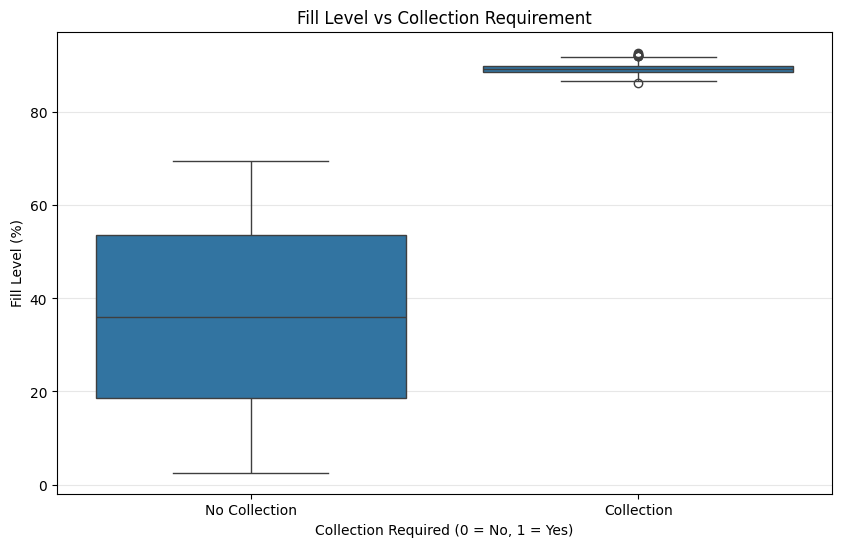

In [15]:
# ==========================================
# STEP 6.1: VISUALIZE TARGET RELATIONSHIP
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="collection_required",
    y="fill_level"
)

plt.title("Fill Level vs Collection Requirement")
plt.xlabel("Collection Required (0 = No, 1 = Yes)")
plt.ylabel("Fill Level (%)")
plt.xticks([0, 1], ["No Collection", "Collection"])
plt.grid(axis="y", alpha=0.3)

plt.show()

In [16]:
# ==========================================
# STEP 6.2: RELATIONSHIP ANALYSIS
# ==========================================

# Fill level by target
print("Fill level by collection decision:")
display(
    df.groupby("collection_required")["fill_level"]
    .agg(["min", "max", "mean", "median"])
)

# Overflow vs collection
print("\nOverflow vs Collection:")
display(pd.crosstab(
    df["collection_required"],
    df["overflow_flag"]
))

# Hazard vs collection
print("\nHazard vs Collection:")
display(pd.crosstab(
    df["collection_required"],
    df["hazard_detected"]
))

# Compaction vs collection
print("\nCompaction vs Collection:")
display(pd.crosstab(
    df["collection_required"],
    df["compaction_status"]
))

# Fill rate vs collection
print("\nFill rate by collection decision:")
display(
    df.groupby("collection_required")["fill_rate"]
    .agg(["mean", "median", "min", "max"])
)

Fill level by collection decision:


,min,max,mean,median
collection_required,,,,
0,2.54,69.55,36.273534,36.045
1,86.30,92.79,89.320643,89.280



Overflow vs Collection:


overflow_flag,0,1
collection_required,,
0,532,0
1,518,166



Hazard vs Collection:


hazard_detected,0,1
collection_required,,
0,532,0
1,156,528



Compaction vs Collection:


compaction_status,High,Low,Medium,Unknown
collection_required,,,,
0,0,266,133,133
1,684,0,0,0



Fill rate by collection decision:


,mean,median,min,max
collection_required,,,,
0,2.100000,2.0,2.0,2.30
1,-0.016667,-0.1,-0.1,0.15


In [17]:

# INVESTIGATE DECISION RULES


# Fill level ranges for each class
print("Fill level ranges:")
display(
    df.groupby("collection_required")["fill_level"]
    .agg(["min", "max", "mean"])
)

# Compaction status vs collection
print("\nCompaction status:")
display(pd.crosstab(
    df["compaction_status"],
    df["collection_required"],
    normalize="index"
).round(3))

# Hazard vs collection
print("\nHazard:")
display(pd.crosstab(
    df["hazard_detected"],
    df["collection_required"],
    normalize="index"
).round(3))

# Overflow vs collection
print("\nOverflow:")
display(pd.crosstab(
    df["overflow_flag"],
    df["collection_required"],
    normalize="index"
).round(3))

# Fill level intervals and target
print("\nFill level intervals:")
df["fill_interval"] = pd.cut(
    df["fill_level"],
    bins=[0, 20, 40, 60, 70, 80, 85, 95, 100]
)

display(pd.crosstab(
    df["fill_interval"],
    df["collection_required"]
))

Fill level ranges:


,min,max,mean
collection_required,,,
0,2.54,69.55,36.273534
1,86.30,92.79,89.320643



Compaction status:


collection_required,0,1
compaction_status,,
High,0.0,1.0
Low,1.0,0.0
Medium,1.0,0.0
Unknown,1.0,0.0



Hazard:


collection_required,0,1
hazard_detected,,
0,0.773,0.227
1,0.000,1.000



Overflow:


collection_required,0,1
overflow_flag,,
0,0.507,0.493
1,0.000,1.000



Fill level intervals:


collection_required,0,1
fill_interval,,
"(0, 20]",133,0
"(20, 40]",133,0
"(40, 60]",133,0
"(60, 70]",133,0
"(85, 95]",0,684


In [18]:

# PREPARE MODELING DATA


# Baseline model: only current fill level
baseline_features = [
    "fill_level"
]

# Enhanced model: sensor and engineered features
enhanced_features = [
    "fill_level",
    "weight",
    "energy_used",
    "fill_rate",
    "weight_rate",
    "predicted_fill_10min"
]

target = "collection_required"

# Keep the necessary columns
model_df = df[
    ["bin_id", "timestamp"] +
    enhanced_features +
    [target]
].copy()

print("Model dataset shape:", model_df.shape)

print("\nMissing values:")
display(model_df.isnull().sum())

print("\nFinal dataset:")
display(model_df.head())

Model dataset shape: (1216, 9)

Missing values:


,0
bin_id,0
timestamp,0
fill_level,0
weight,0
energy_used,0
fill_rate,304
weight_rate,304
predicted_fill_10min,304
collection_required,0



Final dataset:


,bin_id,timestamp,fill_level,weight,energy_used,fill_rate,weight_rate,predicted_fill_10min,collection_required
0,BIN_001,2026-01-01 08:00:00,5.23,1.74,0.0909,NaN,NaN,NaN,0
1,BIN_001,2026-01-01 08:10:00,25.23,8.39,0.1776,2.0,0.665,45.23,0
2,BIN_001,2026-01-01 08:20:00,48.23,16.05,0.2307,2.3,0.766,71.23,0
3,BIN_001,2026-01-01 08:30:00,68.23,22.70,0.3374,2.0,0.665,88.23,0
4,BIN_002,2026-01-01 08:00:00,5.17,1.78,0.0910,NaN,NaN,NaN,0


In [19]:
#split the data

from sklearn.model_selection import train_test_split

# Keep observations where engineered rates are available
dt_data = df[df["rate_available"] == 1].copy()

# Create one stratification label per bin
bin_labels = (
    dt_data.groupby("bin_id")["collection_required"]
    .max()
    .reset_index()
)

# Split BIN IDs, not individual rows
train_bins, test_bins = train_test_split(
    bin_labels["bin_id"],
    test_size=0.20,
    random_state=42,
    stratify=bin_labels["collection_required"]
)

# Separate the observations
train_data = dt_data[dt_data["bin_id"].isin(train_bins)].copy()
test_data = dt_data[dt_data["bin_id"].isin(test_bins)].copy()

print("Training bins:", len(train_bins))
print("Testing bins:", len(test_bins))

print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))

print("\nTraining target distribution:")
display(train_data["collection_required"].value_counts())

print("\nTesting target distribution:")
display(test_data["collection_required"].value_counts())

# Verify that no bin exists in both sets
overlap = set(train_bins) & set(test_bins)

print("\nShared bins between training and testing:", len(overlap))

Training bins: 243
Testing bins: 61
Training observations: 729
Testing observations: 183

Training target distribution:


,count
collection_required,
1,411
0,318



Testing target distribution:


,count
collection_required,
1,102
0,81



Shared bins between training and testing: 0


In [20]:
#tarining decision trees

from sklearn.tree import DecisionTreeClassifier

# Target
y_train = train_data["collection_required"]
y_test = test_data["collection_required"]

# MODEL 1: BASELINE


baseline_features = ["fill_level"]

X_train_baseline = train_data[baseline_features]
X_test_baseline = test_data[baseline_features]

tree_baseline = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree_baseline.fit(X_train_baseline, y_train)

# MODEL 2: ENHANCED


enhanced_features = [
    "fill_level",
    "weight",
    "energy_used",
    "fill_rate",
    "weight_rate",
    "predicted_fill_10min"
]

X_train_enhanced = train_data[enhanced_features]
X_test_enhanced = test_data[enhanced_features]

tree_enhanced = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree_enhanced.fit(X_train_enhanced, y_train)

print("Both Decision Trees have been trained successfully!")

Both Decision Trees have been trained successfully!


In [21]:
# model evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import pandas as pd

# Predictions
y_pred_baseline = tree_baseline.predict(X_test_baseline)
y_pred_enhanced = tree_enhanced.predict(X_test_enhanced)


# EVALUATION FUNCTION


def evaluate_model(name, y_true, y_pred):
    print(f"\n{'='*40}")
    print(f"{name}")
    print(f"{'='*40}")

    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
    print("Recall   :", round(recall_score(y_true, y_pred, zero_division=0), 4))
    print("F1-score :", round(f1_score(y_true, y_pred, zero_division=0), 4))

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=["No Collection (0)", "Collection (1)"],
        zero_division=0
    ))

    print("\nConfusion Matrix:")
    cm = confusion_matrix(y_true, y_pred)
    display(pd.DataFrame(
        cm,
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"]
    ))

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }

# Evaluate baseline
results_baseline = evaluate_model(
    "Baseline Decision Tree",
    y_test,
    y_pred_baseline
)

# Evaluate enhanced
results_enhanced = evaluate_model(
    "Enhanced Decision Tree",
    y_test,
    y_pred_enhanced
)

# MODEL COMPARISON

results_df = pd.DataFrame([
    results_baseline,
    results_enhanced
])

print("\nMODEL COMPARISON ")
display(results_df.round(4))


Baseline Decision Tree
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0

Classification Report:
                   precision    recall  f1-score   support

No Collection (0)       1.00      1.00      1.00        81
   Collection (1)       1.00      1.00      1.00       102

         accuracy                           1.00       183
        macro avg       1.00      1.00      1.00       183
     weighted avg       1.00      1.00      1.00       183


Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,81,0
Actual 1,0,102



Enhanced Decision Tree
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0

Classification Report:
                   precision    recall  f1-score   support

No Collection (0)       1.00      1.00      1.00        81
   Collection (1)       1.00      1.00      1.00       102

         accuracy                           1.00       183
        macro avg       1.00      1.00      1.00       183
     weighted avg       1.00      1.00      1.00       183


Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,81,0
Actual 1,0,102



MODEL COMPARISON 


,Model,Accuracy,Precision,Recall,F1-score
0,Baseline Decision Tree,1.0,1.0,1.0,1.0
1,Enhanced Decision Tree,1.0,1.0,1.0,1.0


In [22]:
from sklearn.tree import export_text

tree_rules = export_text(
    tree_baseline,
    feature_names=baseline_features
)

print(tree_rules)

|--- fill_level <= 77.93
|   |--- class: 0
|--- fill_level >  77.93
|   |--- class: 1



In [23]:
from sklearn.tree import export_text

print("BASELINE DECISION TREE")
print(export_text(tree_baseline, feature_names=baseline_features))

print("\nENHANCED DECISION TREE")
print(export_text(tree_enhanced, feature_names=enhanced_features))

BASELINE DECISION TREE
|--- fill_level <= 77.93
|   |--- class: 0
|--- fill_level >  77.93
|   |--- class: 1


ENHANCED DECISION TREE
|--- weight_rate <= 0.34
|   |--- class: 1
|--- weight_rate >  0.34
|   |--- class: 0



In [24]:
print("Weight rate statistics by collection status:")

display(
    train_data.groupby("collection_required")["weight_rate"]
    .agg(["count", "min", "max", "mean", "median", "std"])
)

print("\nTest data:")
display(
    test_data.groupby("collection_required")["weight_rate"]
    .agg(["count", "min", "max", "mean", "median", "std"])
)

Weight rate statistics by collection status:


,count,min,max,mean,median,std
collection_required,,,,,,
0,318,0.626,0.905,0.749053,0.751,0.073996
1,411,-0.031,0.046,-0.004608,-0.025,0.032756



Test data:


,count,min,max,mean,median,std
collection_required,,,,,,
0,81,0.628,0.900,0.747062,0.747,0.071362
1,102,-0.031,0.046,-0.004657,-0.025,0.033206


In [25]:
# Check whether collection status changes within each bin
status_changes = (
    dt_data.groupby("bin_id")["collection_required"]
    .nunique()
)

print("Bins with changing collection status:",
      (status_changes > 1).sum())

print("Bins with constant collection status:",
      (status_changes == 1).sum())

# Display some examples
display(
    dt_data[
        ["bin_id", "timestamp", "fill_level",
         "weight", "weight_rate", "collection_required"]
    ].sort_values(["bin_id", "timestamp"]).head(15)
)

Bins with changing collection status: 0
Bins with constant collection status: 304


,bin_id,timestamp,fill_level,weight,weight_rate,collection_required
1,BIN_001,2026-01-01 08:10:00,25.23,8.39,0.665,0
2,BIN_001,2026-01-01 08:20:00,48.23,16.05,0.766,0
3,BIN_001,2026-01-01 08:30:00,68.23,22.70,0.665,0
5,BIN_002,2026-01-01 08:10:00,25.17,8.67,0.689,0
6,BIN_002,2026-01-01 08:20:00,48.17,16.58,0.791,0
7,BIN_002,2026-01-01 08:30:00,68.17,23.47,0.689,0
9,BIN_003,2026-01-01 08:10:00,25.55,8.88,0.695,0
10,BIN_003,2026-01-01 08:20:00,48.55,16.88,0.800,0
11,BIN_003,2026-01-01 08:30:00,68.55,23.84,0.696,0
13,BIN_004,2026-01-01 08:10:00,25.18,8.56,0.680,0


In [26]:
# One row per bin
bin_summary = (
    dt_data.groupby("bin_id")
    .agg(
        collection_status=("collection_required", "first"),
        initial_fill=("fill_level", "first"),
        final_fill=("fill_level", "last"),
        initial_weight_rate=("weight_rate", "first"),
        final_weight_rate=("weight_rate", "last")
    )
)

print("Collection status distribution across bins:")
display(bin_summary["collection_status"].value_counts())

print("\nAverage initial and final fill level by collection status:")
display(
    bin_summary.groupby("collection_status")[
        ["initial_fill", "final_fill"]
    ].mean().round(2)
)

Collection status distribution across bins:


,count
collection_status,
1,171
0,133



Average initial and final fill level by collection status:


,initial_fill,final_fill
collection_status,,
0,24.77,67.77
1,88.57,89.07


In [27]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

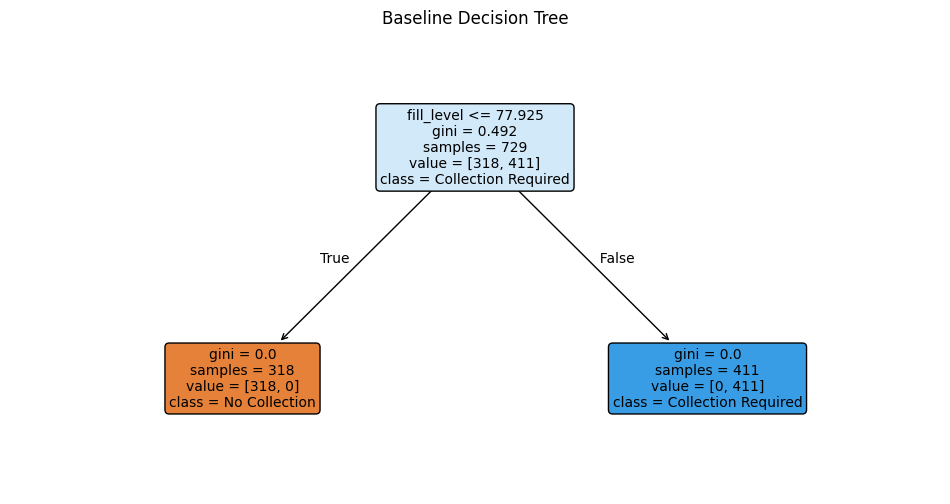

In [28]:
plt.figure(figsize=(12, 6))

plot_tree(
    tree_baseline,
    feature_names=baseline_features,
    class_names=["No Collection", "Collection Required"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Baseline Decision Tree")
plt.show()

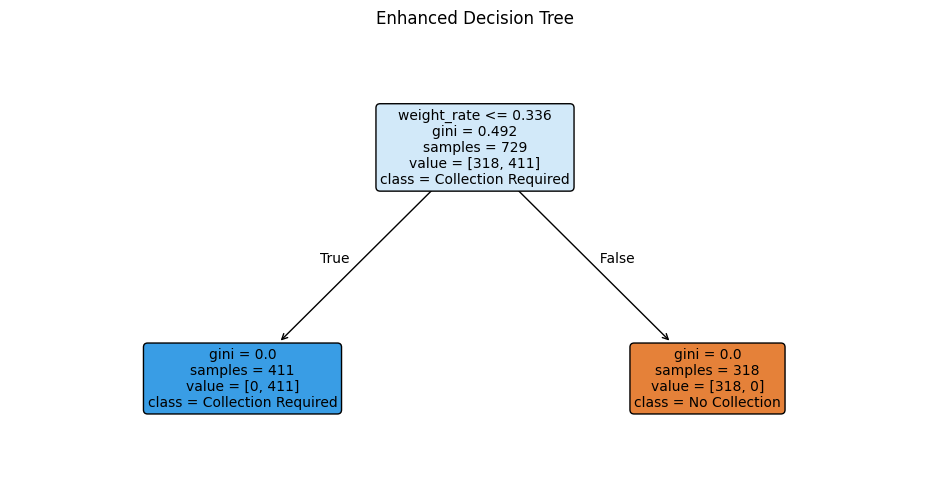

In [29]:
plt.figure(figsize=(12, 6))

plot_tree(
    tree_enhanced,
    feature_names=enhanced_features,
    class_names=["No Collection", "Collection Required"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Enhanced Decision Tree")
plt.show()

In [19]:
!git config --global user.name "samirahammouche"
!git config --global user.email "samirahammouche17@gmail.com"

In [20]:
from google.colab import userdata

TOKEN = userdata.get('gh_token')

In [21]:
import subprocess
import base64

username = "samirahammouche"

auth = base64.b64encode(f"{username}:{TOKEN}".encode()).decode()

!git config --global http.https://github.com/.extraheader "AUTHORIZATION: basic {auth}"

In [22]:
!git clone https://github.com/Nafila1234/smart-waste-multi-agent

Cloning into 'smart-waste-multi-agent'...
remote: Enumerating objects: 58, done.
remote: Counting objects: 100% (58/58), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 58 (delta 15), reused 5 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (58/58), 405.25 KiB | 14.47 MiB/s, done.
Resolving deltas: 100% (15/15), done.


In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
!pwd
!ls -la

/content/smart-waste-multi-agent
total 340
drwxr-xr-x 10 root root   4096 Nov 21 21:12 .
drwxr-xr-x  1 root root   4096 Nov 21 21:07 ..
drwxr-xr-x  2 root root   4096 Nov 21 21:07 app
drwxr-xr-x  2 root root   4096 Nov 21 21:07 data
drwxr-xr-x  8 root root   4096 Nov 21 21:09 .git
-rw-r--r--  1 root root     55 Nov 21 21:07 .gitignore
drwxr-xr-x  2 root root   4096 Nov 21 21:07 prediction_agent
-rw-r--r--  1 root root 294428 Nov 21 21:07 preprocessing_data.ipynb
-rw-r--r--  1 root root   5147 Nov 21 21:07 README.md
drwxr-xr-x  2 root root   4096 Nov 21 21:07 regression-lineaire
drwxr-xr-x  2 root root   4096 Nov 21 21:07 routing_agent
drwxr-xr-x  9 root root   4096 Nov 21 21:12 smart-waste-multi-agent
drwxr-xr-x  2 root root   4096 Nov 21 21:07 visual_agent


In [26]:
!find "/content/drive/MyDrive" -name "*.ipynb"

/content/drive/MyDrive/Colab Notebooks/preprocessing_data+decision_tree_model.ipynb
/content/drive/MyDrive/Colab Notebooks/Copie de TP5 FIA.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
/content/drive/MyDrive/Colab Notebooks/gpt_transformer.ipynb
/content/drive/MyDrive/Colab Notebooks/bert_pretrained.ipynb
/content/drive/MyDrive/Colab Notebooks/bert3.ipynb
/content/drive/MyDrive/Colab Notebooks/diffuser_model.ipynb
/content/drive/MyDrive/Colab Notebooks/first_aid_assistant.ipynb
/content/drive/MyDrive/Colab Notebooks/correct_first_aid_assistant.ipynb
/content/drive/MyDrive/Colab Notebooks/desc_generator.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled2.ipynb
/content/drive/MyDrive/Colab Notebooks/imageProcessor.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled3.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled4.ipynb
/content/drive/MyDrive/Colab Notebooks/Copie de marketing.ipynb
/content/drive/MyDrive/C

In [28]:
!cp "/content/drive/MyDrive/Colab Notebooks/preprocessing_data+decision_tree_model.ipynb" "/content/smart-waste-multi-agent/prediction_agent/"

In [29]:
!ls /content

drive  sample_data  smart-waste-multi-agent


In [31]:
%cd "/content/smart-waste-multi-agent/"

!git add prediction_agent/preprocessing_data+decision_tree_model.ipynb
!git commit -m "Add Decision Tree collection prediction model"
!git push origin main

/content/smart-waste-multi-agent
[main 3dd0800] Add Decision Tree collection prediction model
 1 file changed, 1 insertion(+)
 create mode 100644 prediction_agent/preprocessing_data+decision_tree_model.ipynb
remote: Permission to Nafila1234/smart-waste-multi-agent.git denied to samirahammouche.
fatal: unable to access 'https://github.com/Nafila1234/smart-waste-multi-agent/': The requested URL returned error: 403


In [33]:
from google.colab import userdata
import requests

token = userdata.get("gh_token")

headers = {"Authorization": f"Bearer {token}"}

r = requests.get(
    "https://api.github.com/repos/Nafila1234/smart-waste-multi-agent",
    headers=headers
)

print("Status:", r.status_code)

if r.status_code == 200:
    print("Permissions:", r.json()["permissions"])
else:
    print(r.text)

Status: 200
Permissions: {'admin': False, 'maintain': False, 'push': True, 'triage': True, 'pull': True}


In [34]:
%cd /content/smart-waste-multi-agent

!git add "prediction_agent/preprocessing_data+decision_tree_model.ipynb"
!git commit -m "Add Decision Tree collection prediction model"

/content/smart-waste-multi-agent
On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	smart-waste-multi-agent/

nothing added to commit but untracked files present (use "git add" to track)


In [41]:
import subprocess
import base64
from google.colab import userdata

# Your GitHub credentials
username = "samirahammouche"
repository = "Nafila1234/smart-waste-multi-agent"
token = userdata.get("gh_token")

# Encode authentication
auth = base64.b64encode(
    f"{username}:{token}".encode()
).decode()

# Go to your repository
%cd /content/smart-waste-multi-agent

# Remove old conflicting authorization headers
for scope in ["--local", "--global"]:
    subprocess.run(
        ["git", "config", scope, "--unset-all",
         "http.https://github.com/.extraheader"],
        stderr=subprocess.DEVNULL
    )

# Add your notebook
subprocess.run(
    ["git", "add", "prediction_agent/preprocessing_data+decision_tree_model.ipynb"],
    check=True
)

# Commit changes
subprocess.run(
    ["git", "commit", "-m", "Add Decision Tree collection prediction model"]
)

# Push to your teammate's repository
result = subprocess.run(
    [
        "git",
        "-c", "credential.helper=",
        "-c", f"http.https://github.com/.extraheader=AUTHORIZATION: basic {auth}",
        "push",
        "https://github.com/Nafila1234/smart-waste-multi-agent.git",
        "main"
    ],
    capture_output=True,
    text=True
)

print("OUTPUT:", result.stdout)
print("ERROR:", result.stderr)
print("RETURN CODE:", result.returncode)

/content/smart-waste-multi-agent
OUTPUT: 
ERROR: remote: Permission to Nafila1234/smart-waste-multi-agent.git denied to samirahammouche.
fatal: unable to access 'https://github.com/Nafila1234/smart-waste-multi-agent.git/': The requested URL returned error: 403

RETURN CODE: 128


In [38]:
!git push origin main

fatal: could not read Username for 'https://github.com': No such device or address
